In [2]:
# ============================================================
# BÀI 4: PHÂN LOẠI CHẤT LƯỢNG RƯỢU VANG ĐỎ
# Họ và tên: Nguyễn Công Vũ
# MSSV: 6451071089
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import tree, metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB

# 1. Đọc dữ liệu
data = pd.read_csv('/content/winequality-red.csv', sep=',')

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 2. Hiển thị thông tin dữ liệu
print("\n1. KÍCH THƯỚC DỮ LIỆU:")
print(data.shape)

print("\n2. DANH SÁCH CÁC THUỘC TÍNH:")
print(data.columns.tolist())

print("\n3. THÔNG TIN DỮ LIỆU:")
data.info()

print("\n4. KIỂM TRA GIÁ TRỊ THIẾU:")
print(data.isnull().sum())

print("\n5. 5 DÒNG DỮ LIỆU ĐẦU TIÊN:")
display(data.head())

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. KÍCH THƯỚC DỮ LIỆU:
(1599, 12)

2. DANH SÁCH CÁC THUỘC TÍNH:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

3. THÔNG TIN DỮ LIỆU:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates    

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
# ============================================================
# CÂU 4: XÁC ĐỊNH THUỘC TÍNH ĐẦU VÀO VÀ ĐẦU RA
# ============================================================

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 1. Xác định biến mục tiêu
target = 'quality'

# 2. Xác định tập thuộc tính đầu vào
features = data.drop(columns=[target])

# 3. Xác định biến đầu ra
y = data[target]

print("\n1. CÁC THUỘC TÍNH ĐẦU VÀO (X):")
print(features.columns.tolist())

print("\nSố lượng thuộc tính đầu vào:", features.shape[1])

print("\n2. THUỘC TÍNH ĐẦU RA (Y):")
print(target)

print("\n3. CÁC GIÁ TRỊ CỦA QUALITY:")
print(y.unique())

print("\n4. KÍCH THƯỚC DỮ LIỆU:")
print("X:", features.shape)
print("y:", y.shape)

print("\nHOÀN THÀNH CÂU 4!")

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. CÁC THUỘC TÍNH ĐẦU VÀO (X):
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Số lượng thuộc tính đầu vào: 11

2. THUỘC TÍNH ĐẦU RA (Y):
quality

3. CÁC GIÁ TRỊ CỦA QUALITY:
[5 6 7 4 8 3]

4. KÍCH THƯỚC DỮ LIỆU:
X: (1599, 11)
y: (1599,)

HOÀN THÀNH CÂU 4!


In [4]:
# ============================================================
# CÂU 5: KIỂM TRA VÀ CHUYỂN ĐỔI KIỂU DỮ LIỆU
# ============================================================

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 1. Xác định các thuộc tính không phải dạng số
categorical_cols = features.select_dtypes(
    exclude=['int64', 'float64']
).columns

print("\n1. CÁC THUỘC TÍNH KHÔNG PHẢI DẠNG SỐ:")
print(categorical_cols.tolist())

print("Số lượng thuộc tính:", len(categorical_cols))

# 2. Kiểm tra kiểu dữ liệu các thuộc tính
print("\n2. KIỂU DỮ LIỆU CỦA CÁC THUỘC TÍNH:")
print(features.dtypes)

# 3. Kết quả
if len(categorical_cols) == 0:
    print("\n3. TẤT CẢ THUỘC TÍNH ĐÃ Ở DẠNG SỐ.")
    print("KHÔNG CẦN THỰC HIỆN ONE-HOT ENCODING.")

print("\nHOÀN THÀNH CÂU 5!")

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. CÁC THUỘC TÍNH KHÔNG PHẢI DẠNG SỐ:
[]
Số lượng thuộc tính: 0

2. KIỂU DỮ LIỆU CỦA CÁC THUỘC TÍNH:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object

3. TẤT CẢ THUỘC TÍNH ĐÃ Ở DẠNG SỐ.
KHÔNG CẦN THỰC HIỆN ONE-HOT ENCODING.

HOÀN THÀNH CÂU 5!


Dataset Red Wine Quality có 11 thuộc tính đầu vào đều thuộc kiểu dữ liệu số. Vì vậy, không cần sử dụng One-Hot Encoding để chuyển đổi dữ liệu. Các thuộc tính đã phù hợp để đưa vào mô hình học máy.

In [5]:
# ============================================================
# CÂU 6: CHIA DỮ LIỆU HUẤN LUYỆN VÀ KIỂM THỬ
# ============================================================

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 1. Chia dữ liệu thành hai tập
X_train, X_test, y_train, y_test = train_test_split(
    features,
    y,
    test_size=0.3,
    random_state=42
)

# 2. Hiển thị kích thước dữ liệu
print("\n1. KÍCH THƯỚC DỮ LIỆU BAN ĐẦU:")
print("X:", features.shape)
print("y:", y.shape)

print("\n2. KÍCH THƯỚC DỮ LIỆU HUẤN LUYỆN:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\n3. KÍCH THƯỚC DỮ LIỆU KIỂM THỬ:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\n4. TỶ LỆ CHIA DỮ LIỆU:")
print("Huấn luyện: {:.0f}%".format(len(X_train) / len(features) * 100))
print("Kiểm thử: {:.0f}%".format(len(X_test) / len(features) * 100))


Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. KÍCH THƯỚC DỮ LIỆU BAN ĐẦU:
X: (1599, 11)
y: (1599,)

2. KÍCH THƯỚC DỮ LIỆU HUẤN LUYỆN:
X_train: (1119, 11)
y_train: (1119,)

3. KÍCH THƯỚC DỮ LIỆU KIỂM THỬ:
X_test: (480, 11)
y_test: (480,)

4. TỶ LỆ CHIA DỮ LIỆU:
Huấn luyện: 70%
Kiểm thử: 30%


Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. HUẤN LUYỆN MÔ HÌNH ID3 THÀNH CÔNG

2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH
Accuracy: 0.5833333333333334

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480


3. MA TRẬN NHẦM LẪN:
[[  0   1   0   0   0   0]
 [  0   2   8   7   0   0]
 [  2  14 129  43   7   0]
 [  0   7  44 120  28   1]
 [  0   0   3  28  28   2]
 [  0   0   1   2   2   1]]


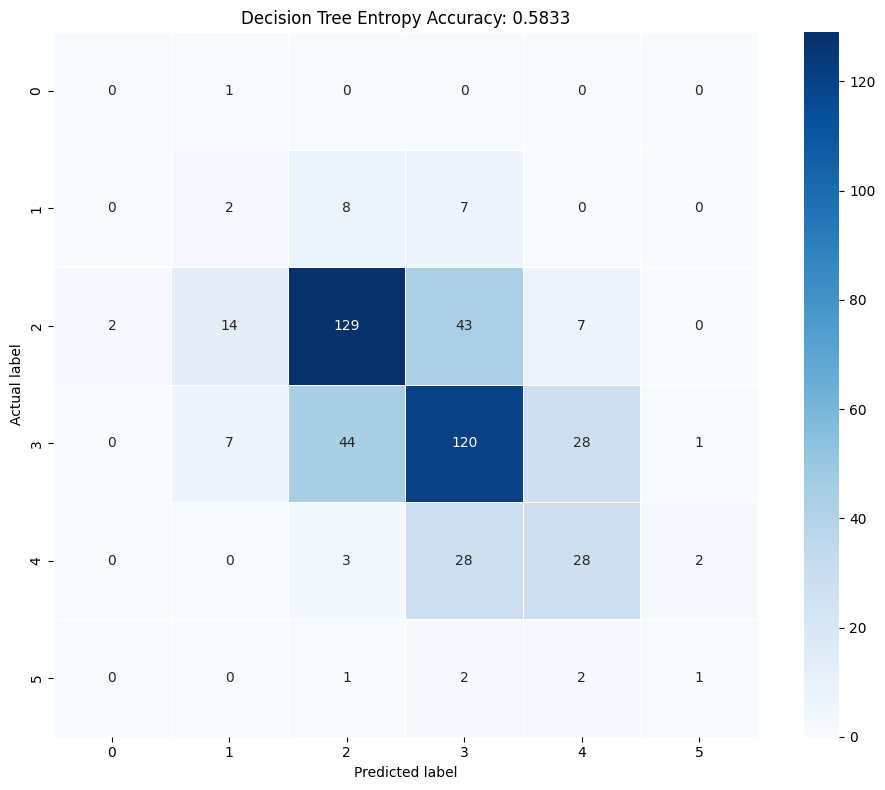

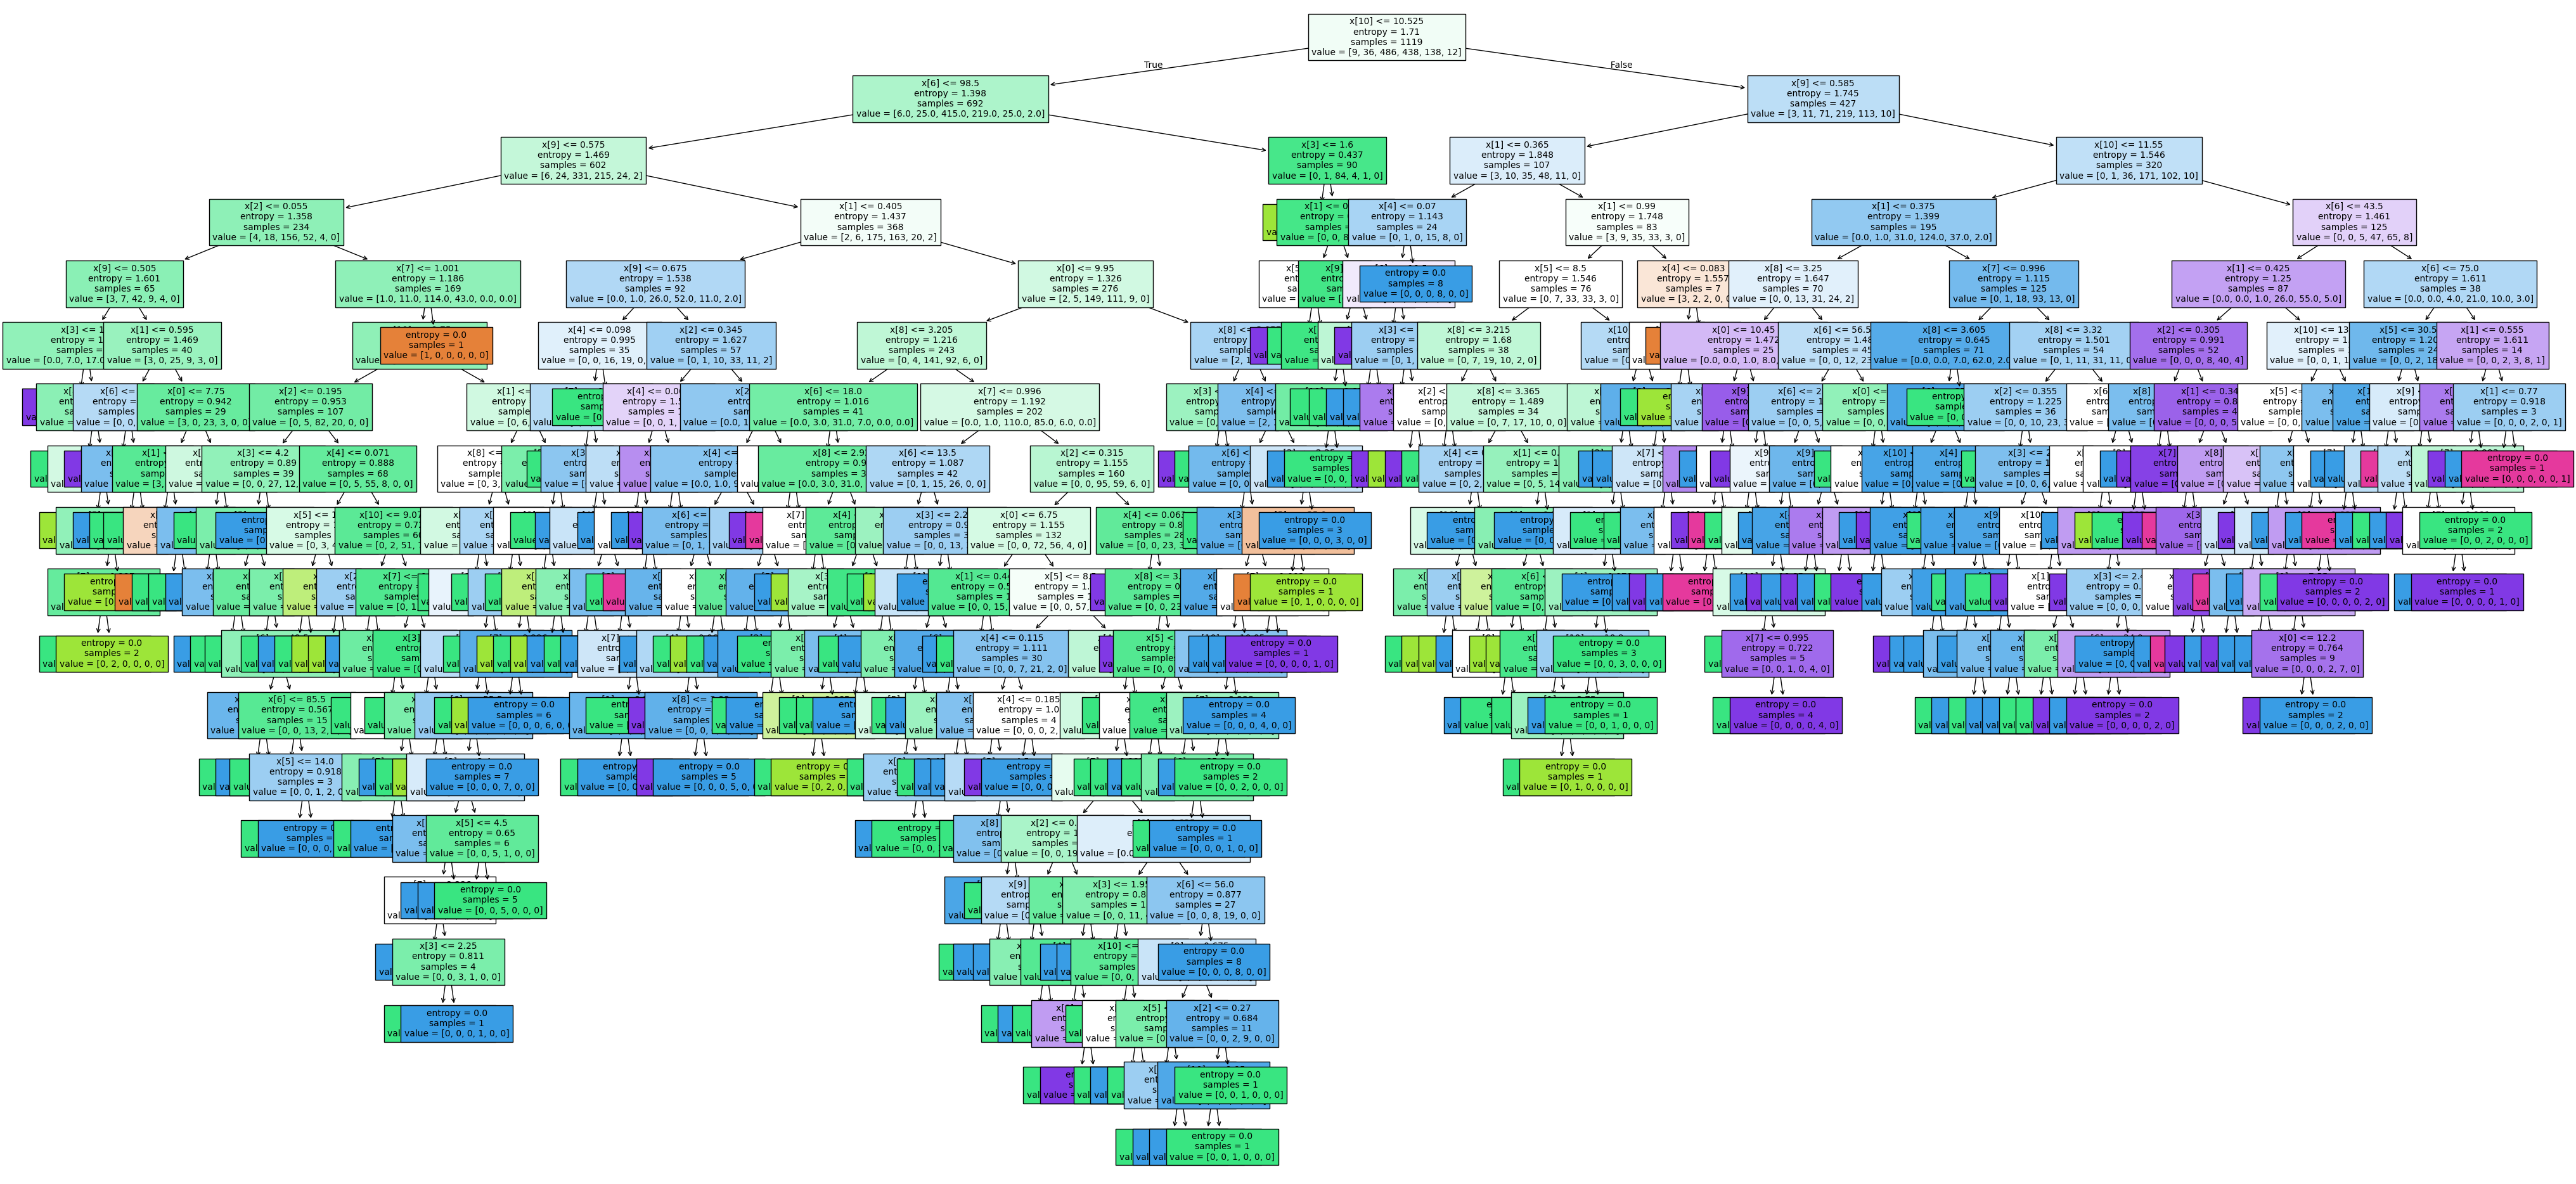


4. ĐÃ LƯU CÂY QUYẾT ĐỊNH: decision_tree_entropy_wine.png


In [6]:
# ============================================================
# CÂU 7: XÂY DỰNG CÂY QUYẾT ĐỊNH ID3 (ENTROPY)
# ============================================================

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 1. Khởi tạo và huấn luyện mô hình Decision Tree
clf = tree.DecisionTreeClassifier(
    criterion='entropy',
    random_state=0
)

clf.fit(X_train, y_train)

print("\n1. HUẤN LUYỆN MÔ HÌNH ID3 THÀNH CÔNG")

# 2. Dự đoán dữ liệu kiểm thử
tree_pred = clf.predict(X_test)

# 3. Đánh giá mô hình
tree_score = metrics.accuracy_score(y_test, tree_pred)

print("\n2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH")
print("Accuracy:", tree_score)

print("\nClassification Report:")
print(metrics.classification_report(y_test, tree_pred, zero_division=0))

# 4. Tính ma trận nhầm lẫn
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

print("\n3. MA TRẬN NHẦM LẪN:")
print(tree_cm)

# 5. Biểu diễn ma trận nhầm lẫn bằng Heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt='d',
    linewidths=0.5,
    square=True,
    cmap='Blues'
)

plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title(f'Decision Tree Entropy Accuracy: {tree_score:.4f}')
plt.tight_layout()
plt.show()

# 6. Vẽ và lưu cây quyết định
plt.figure(figsize=(50, 24))

tree.plot_tree(
    clf,
    filled=True,
    fontsize=10
)

plt.savefig('decision_tree_entropy_wine.png', dpi=100)
plt.show()

print("\n4. ĐÃ LƯU CÂY QUYẾT ĐỊNH: decision_tree_entropy_wine.png")


Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. HUẤN LUYỆN MÔ HÌNH GINI THÀNH CÔNG

2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH
Accuracy: 0.5625

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480


3. MA TRẬN NHẦM LẪN:
[[  0   0   1   0   0   0]
 [  0   1  11   4   1   0]
 [  1   9 121  59   4   1]
 [  0   3  50 116  30   1]
 [  0   1   5  23  30   2]
 [  0   0   0   2   2   2]]


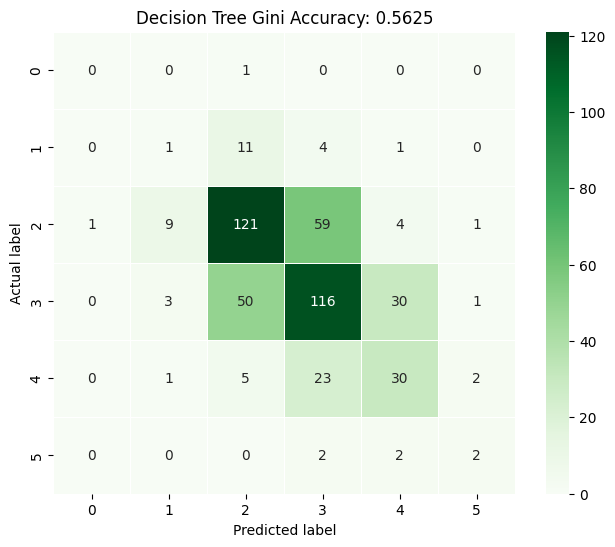

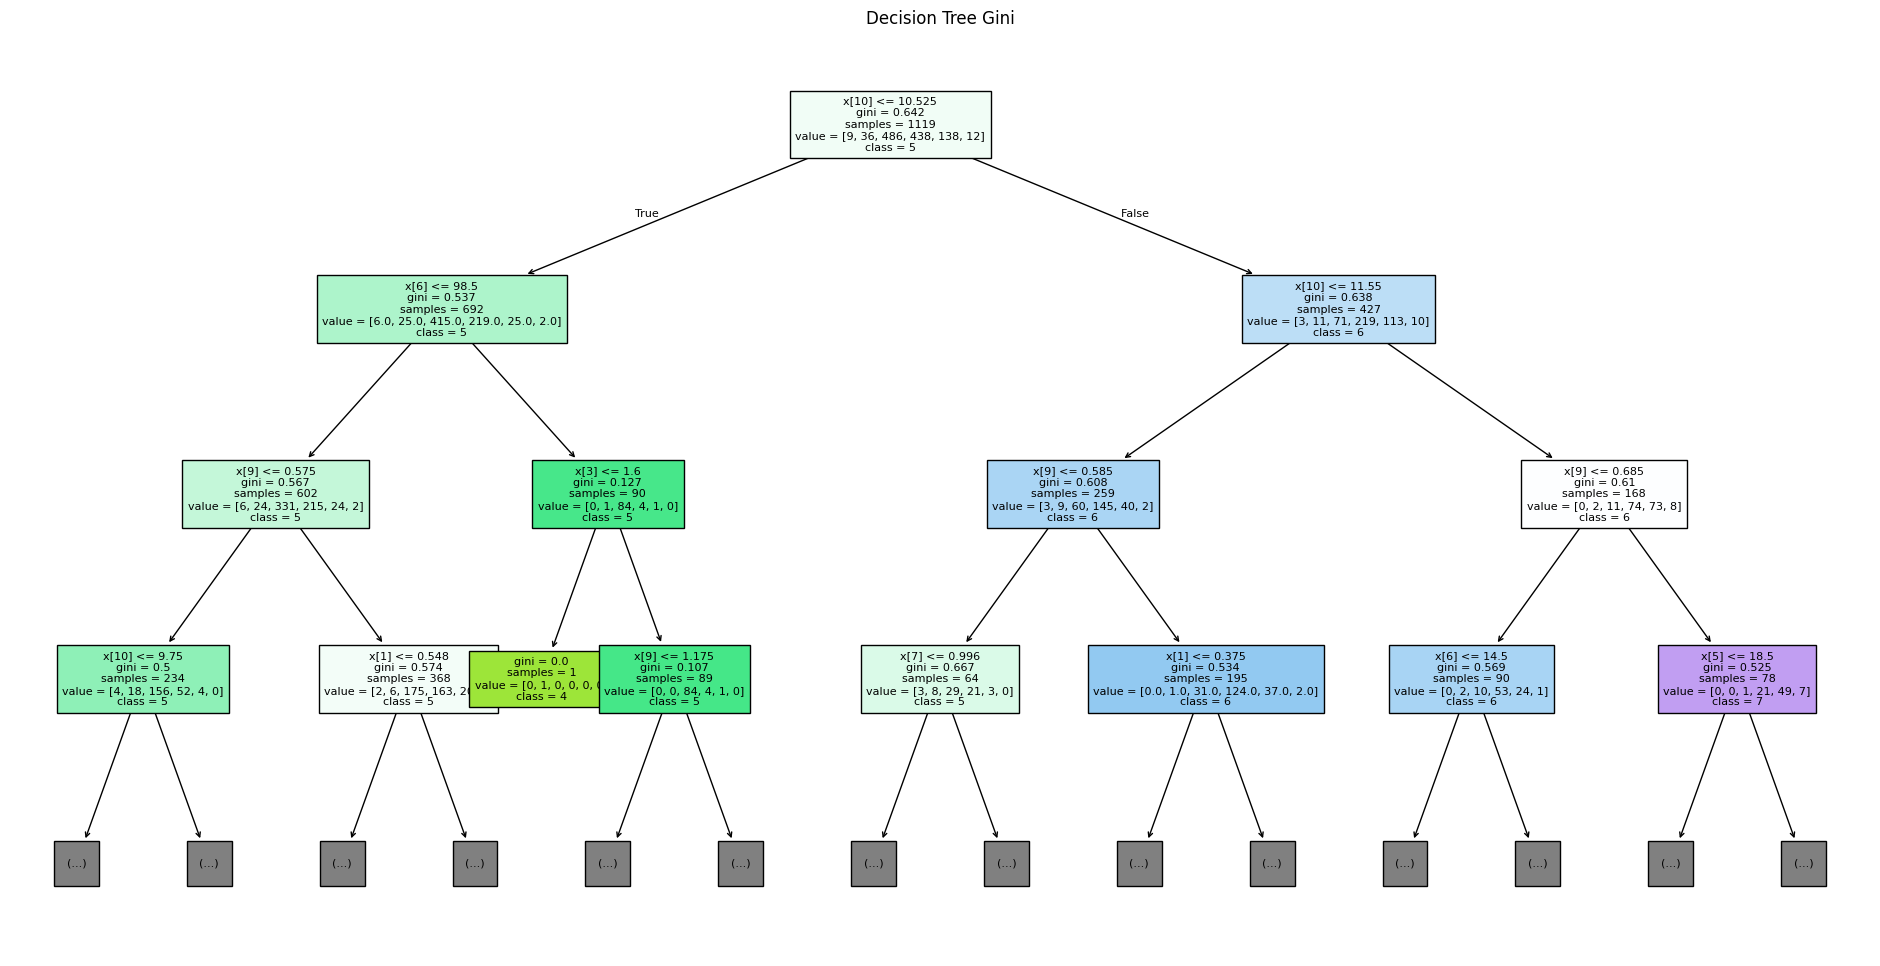

In [8]:
# ============================================================
# CÂU 8: XÂY DỰNG CÂY QUYẾT ĐỊNH VỚI GINI
# ============================================================

from sklearn.metrics import accuracy_score

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 1. Khởi tạo và huấn luyện mô hình Decision Tree
clf_gini = tree.DecisionTreeClassifier(
    criterion='gini',
    random_state=0
)

clf_gini.fit(X_train, y_train)

print("\n1. HUẤN LUYỆN MÔ HÌNH GINI THÀNH CÔNG")

# 2. Dự đoán dữ liệu kiểm thử
gini_pred = clf_gini.predict(X_test)

# 3. Đánh giá mô hình
gini_score = accuracy_score(y_test, gini_pred)

print("\n2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH")
print("Accuracy:", gini_score)

print("\nClassification Report:")
print(metrics.classification_report(y_test, gini_pred))

# 4. Tính ma trận nhầm lẫn
gini_cm = metrics.confusion_matrix(y_test, gini_pred)

print("\n3. MA TRẬN NHẦM LẪN:")
print(gini_cm)

# 5. Biểu diễn ma trận nhầm lẫn
plt.figure(figsize=(8, 6))

sns.heatmap(
    gini_cm,
    annot=True,
    fmt='d',
    linewidths=0.5,
    square=True,
    cmap='Greens'
)

plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title(f'Decision Tree Gini Accuracy: {gini_score:.4f}')
plt.show()

# 6. Vẽ cây quyết định (giới hạn độ sâu để dễ quan sát)
plt.figure(figsize=(24, 12))

tree.plot_tree(
clf_gini,
filled=True,
fontsize=8,
max_depth=3,
class_names=[str(i) for i in clf_gini.classes_]
)

plt.title('Decision Tree Gini')
plt.show()


Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. HUẤN LUYỆN MÔ HÌNH NAIVE BAYES THÀNH CÔNG

2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH
Accuracy: 0.5416666666666666

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480


3. MA TRẬN NHẦM LẪN:
[[  0   0   1   0   0   0]
 [  1   2   8   6   0   0]
 [  0   6 121  63   5   0]
 [  0   9  46 107  35   3]
 [  0   0   3  28  30   0]
 [  0   0   0   1   5   0]]


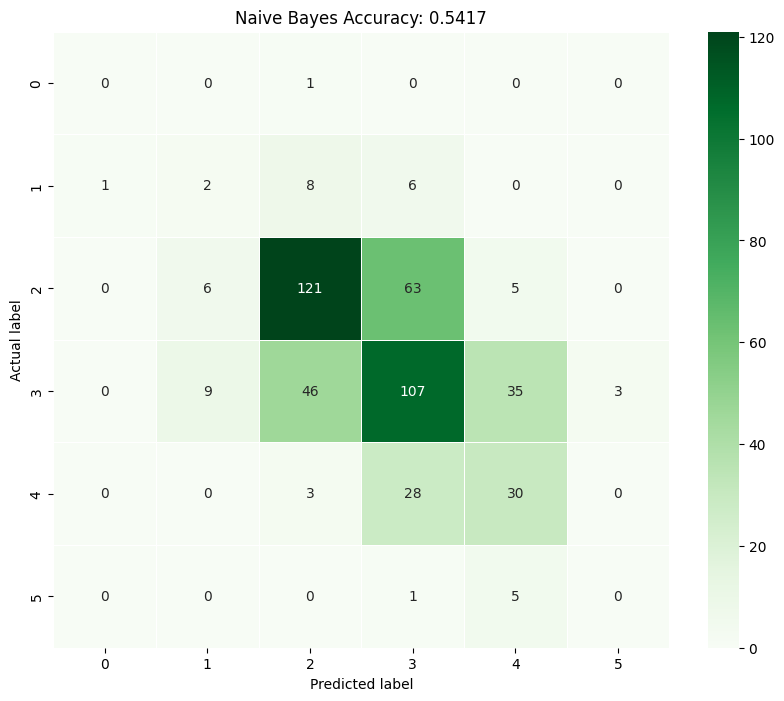


HOÀN THÀNH CÂU 9!


In [9]:
# ============================================================
# CÂU 9: XÂY DỰNG MÔ HÌNH NAIVE BAYES
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 55)

# 1. Khởi tạo và huấn luyện mô hình Naive Bayes
gnb = GaussianNB()

gnb.fit(X_train, y_train)

print("\n1. HUẤN LUYỆN MÔ HÌNH NAIVE BAYES THÀNH CÔNG")

# 2. Dự đoán dữ liệu kiểm thử
bayes_pred = gnb.predict(X_test)

# 3. Đánh giá mô hình
bayes_score = accuracy_score(y_test, bayes_pred)

print("\n2. KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH")
print("Accuracy:", bayes_score)

print("\nClassification Report:")
print(metrics.classification_report(y_test, bayes_pred))

# 4. Tính ma trận nhầm lẫn
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

print("\n3. MA TRẬN NHẦM LẪN:")
print(bayes_cm)

# 5. Biểu diễn ma trận nhầm lẫn bằng Heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    bayes_cm,
    annot=True,
    fmt='d',
    linewidths=0.5,
    square=True,
    cmap='Greens'
)

plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title(f'Naive Bayes Accuracy: {bayes_score:.4f}')
plt.show()


Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089

1. BẢNG SO SÁNH ĐỘ CHÍNH XÁC:
Decision Tree (Entropy): 0.5979 (59.79%)
Decision Tree (Gini): 0.5729 (57.29%)
Naive Bayes: 0.5417 (54.17%)

2. MÔ HÌNH CÓ ACCURACY CAO NHẤT:
Decision Tree (Entropy)
Accuracy: 0.5979


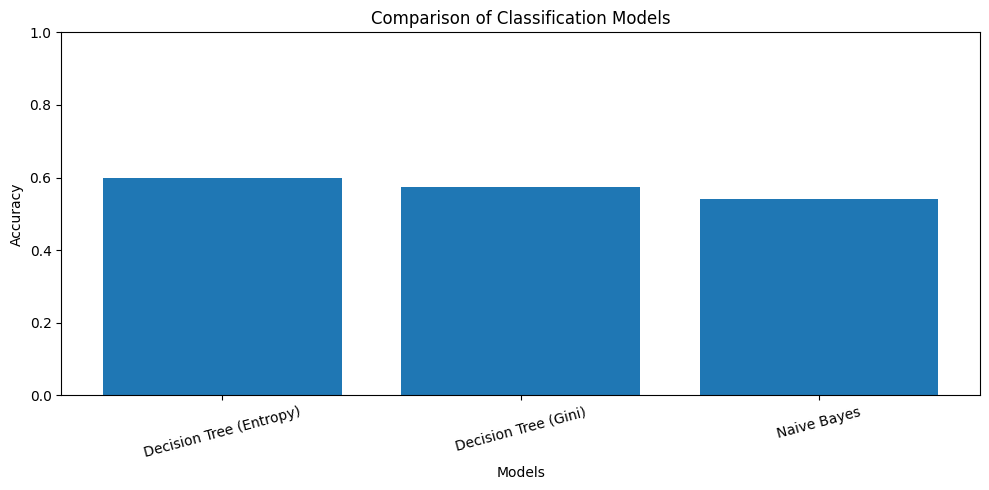

In [13]:
# ============================================================
# CÂU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# 1. Huấn luyện 3 mô hình
model_entropy = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model_gini = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

model_bayes = GaussianNB()

model_entropy.fit(X_train, y_train)
model_gini.fit(X_train, y_train)
model_bayes.fit(X_train, y_train)

# 2. Dự đoán và tính Accuracy
models = {
    'Decision Tree (Entropy)': accuracy_score(
        y_test, model_entropy.predict(X_test)
    ),
    'Decision Tree (Gini)': accuracy_score(
        y_test, model_gini.predict(X_test)
    ),
    'Naive Bayes': accuracy_score(
        y_test, model_bayes.predict(X_test)
    )
}

print("\n1. BẢNG SO SÁNH ĐỘ CHÍNH XÁC:")

for name, score in models.items():
    print(f"{name}: {score:.4f} ({score * 100:.2f}%)")

# 3. Xác định mô hình tốt nhất
best_model = max(models, key=models.get)

print("\n2. MÔ HÌNH CÓ ACCURACY CAO NHẤT:")
print(best_model)
print(f"Accuracy: {models[best_model]:.4f}")

# 4. Vẽ biểu đồ so sánh
plt.figure(figsize=(10, 5))

plt.bar(models.keys(), models.values())

plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Comparison of Classification Models')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
